<a href="https://colab.research.google.com/github/UsmanUmair1/ATM-MACHINE/blob/main/Student_Academic_Performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ucimlrepo -q

from ucimlrepo import fetch_ucirepo

student_performance = fetch_ucirepo(id=320)  # Student Performance dataset
X = student_performance.data.features
y = student_performance.data.targets
df = X.join(y)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import urllib.request
import zipfile
import io

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"

# Download and open the ZIP file in memory
with urllib.request.urlopen(url) as response:
    with zipfile.ZipFile(io.BytesIO(response.read())) as z:
        # Read 'student-mat.csv' (or replace with 'student-por.csv')
        with z.open("student-mat.csv") as f:
            df = pd.read_csv(f, sep=";")

In [ ]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
df.shape

(395, 33)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [ ]:
df.columns.tolist()

['school',
 'sex',
 'age',
 'address',
 'famsize',
 'Pstatus',
 'Medu',
 'Fedu',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'traveltime',
 'studytime',
 'failures',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic',
 'famrel',
 'freetime',
 'goout',
 'Dalc',
 'Walc',
 'health',
 'absences',
 'G1',
 'G2',
 'G3']

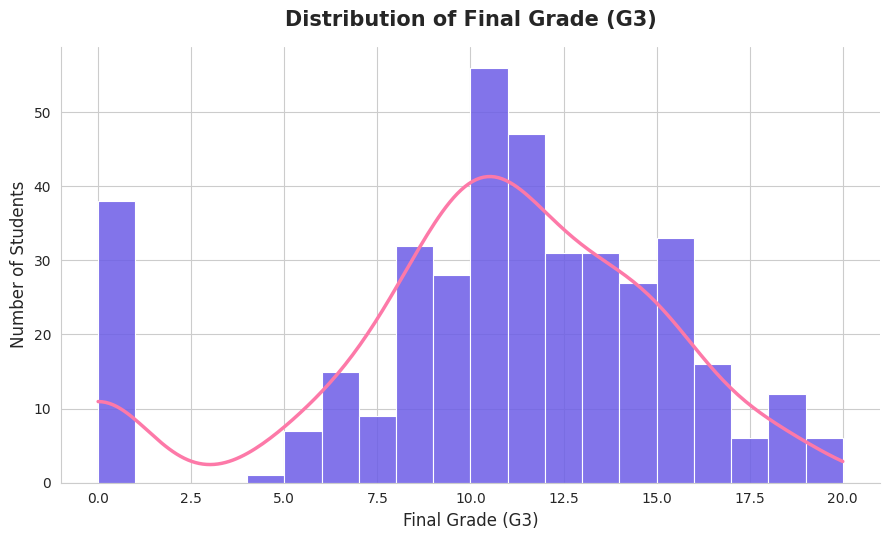

In [ ]:
# 1. Distribution of G3
sns.set_style("whitegrid")
plt.figure(figsize=(9, 5.5))
ax = sns.histplot(
    df['G3'],
    bins=20,
    kde=True,
    color="#6C5CE7",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.85
)
if ax.lines:
    ax.lines[0].set_color("#FD79A8")
    ax.lines[0].set_linewidth(2.5)

plt.title("Distribution of Final Grade (G3)", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Final Grade (G3)", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)
plt.gca().spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
print(df['G3'].describe())
print("\nSkewness:", df['G3'].skew())

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Skewness: -0.7326723530443435


In [ ]:
df = df[df['G3'] > 0].reset_index(drop=True)
print(df.shape)

(357, 33)


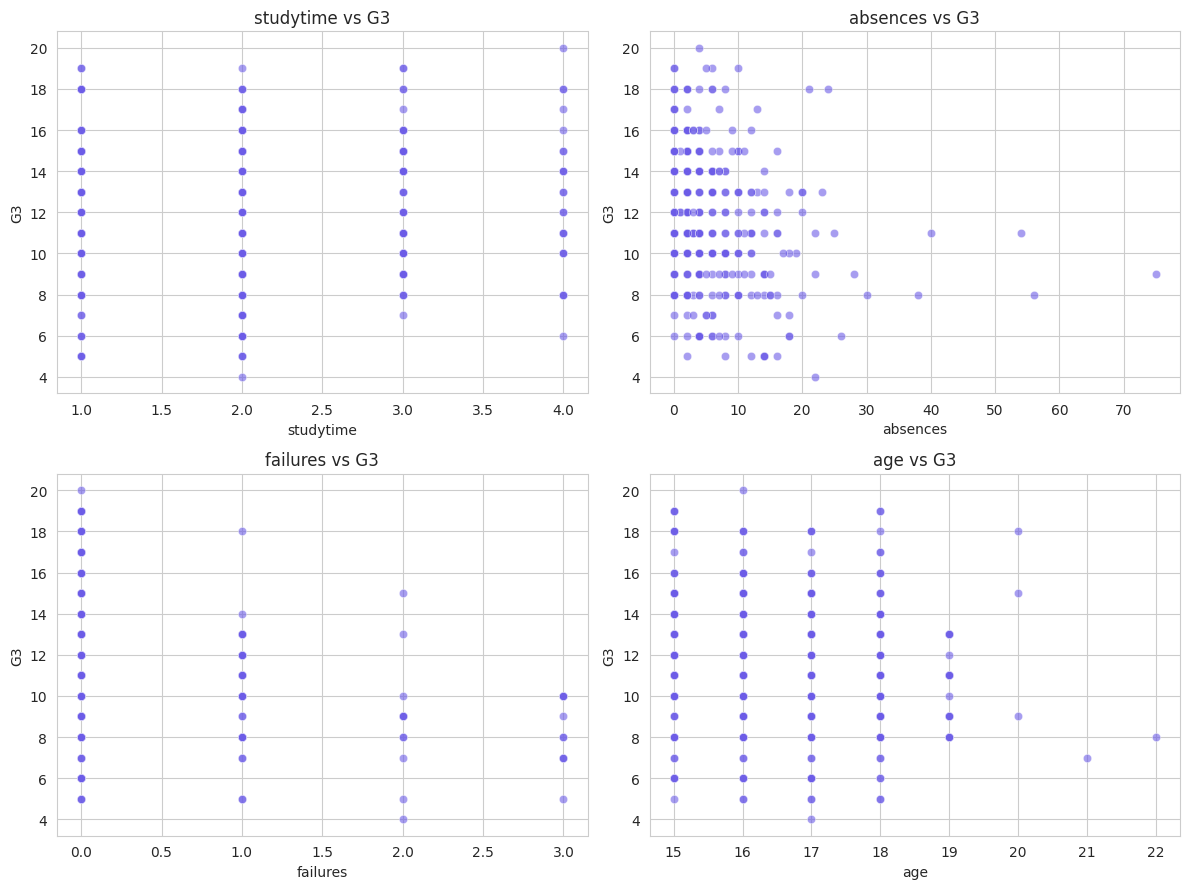

/tmp/ipykernel_2131/1969635061.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[feat], y=df['G3'], ax=ax, palette="pastel")
/tmp/ipykernel_2131/1969635061.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[feat], y=df['G3'], ax=ax, palette="pastel")
/tmp/ipykernel_2131/1969635061.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[feat], y=df['G3'], ax=ax, palette="pastel")
/tmp/ipykernel_2131/1969635061.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assig

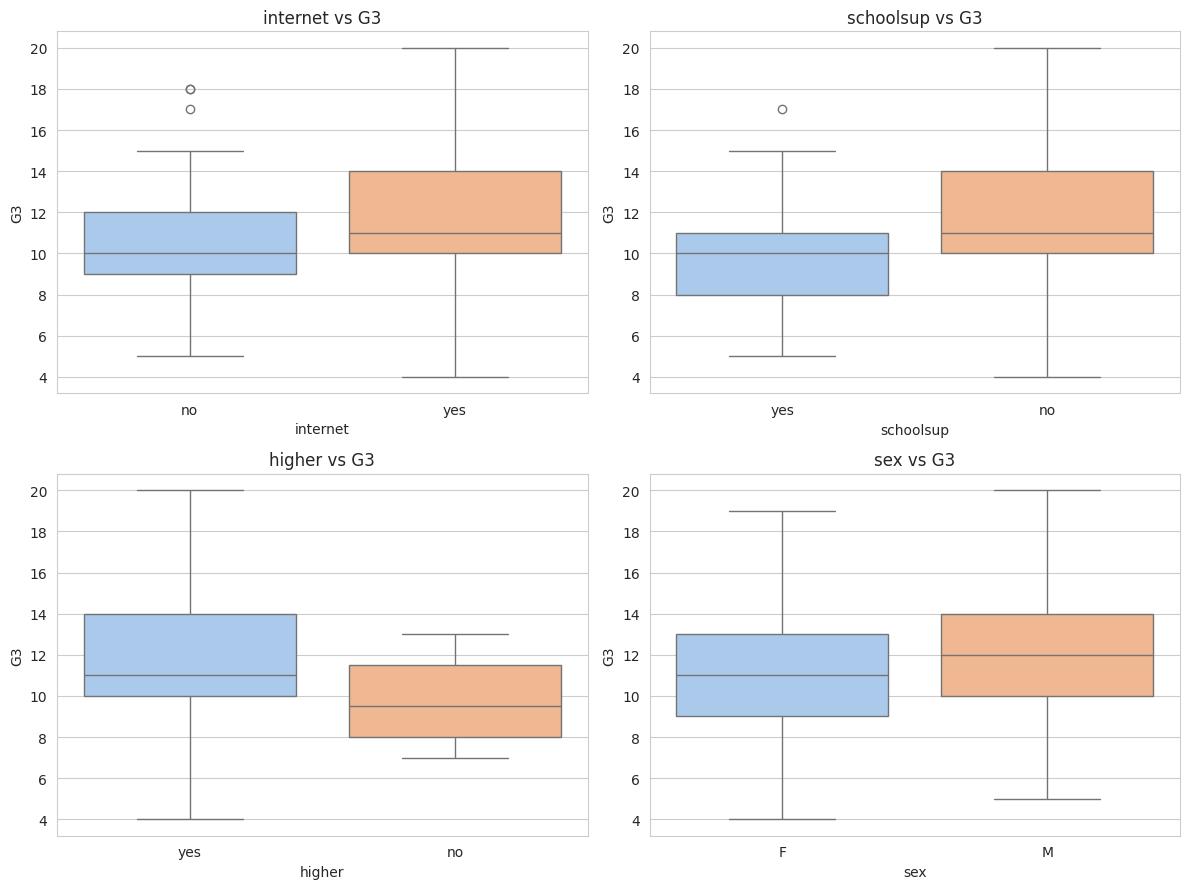

In [ ]:
#Bivariate Analysis
numeric_feats = ['studytime', 'absences', 'failures', 'age']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, feat in zip(axes.flatten(), numeric_feats):
    sns.scatterplot(x=df[feat], y=df['G3'], ax=ax, alpha=0.6, color="#6C5CE7")
    ax.set_title(f'{feat} vs G3')
plt.tight_layout()
plt.show()

cat_feats = ['internet', 'schoolsup', 'higher', 'sex']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, feat in zip(axes.flatten(), cat_feats):
    sns.boxplot(x=df[feat], y=df['G3'], ax=ax, palette="pastel")
    ax.set_title(f'{feat} vs G3')
plt.tight_layout()
plt.show()

In [ ]:
#Handle missing values ​​and perform encoding
print(df.isnull().sum().sum())
print(df.isnull().sum()[df.isnull().sum() > 0])

0
Series([], dtype: int64)


In [ ]:
print(df['Medu'].unique())
print(df['failures'].unique())
print(df['studytime'].unique())

[4 1 3 2 0]
[0 3 2 1]
[2 3 1 4]


In [ ]:
# Ordinal feature definitions (already integer-encoded by dataset creators):
# Medu / Fedu (parental education): 0=none, 1=primary (4th grade), 2=5th-9th grade, 3=secondary, 4=higher education
# studytime: 1=<2 hours, 2=2-5 hours, 3=5-10 hours, 4=>10 hours
# failures: 0,1,2,3 = number of past class failures (3 = "3 or more")
# famrel, freetime, goout, Dalc, Walc, health: 1 (very low/bad) to 5 (very high/good)

In [ ]:
# Binary columns → label encode (map yes/no, M/F, etc. to 0/1)
binary_cols = ['schoolsup', 'famsup', 'paid', 'activities', 'nursery',
               'higher', 'internet', 'romantic', 'sex', 'address',
               'famsize', 'Pstatus']
for col in binary_cols:
    df[col] = df[col].astype('category').cat.codes

    # Nominal columns → one-hot encode
nominal_cols = ['Mjob', 'Fjob', 'reason', 'guardian', 'school']
df = pd.get_dummies(df, columns=nominal_cols, drop_first=True)

# Ordinal columns (Medu, Fedu, studytime, failures, famrel, freetime, goout, Dalc, Walc, health)
# — already integer-encoded, no action needed, just documented (see earlier comment block)

print(df.shape)
print(df.dtypes)

(357, 42)
sex                   int8
age                  int64
address               int8
famsize               int8
Pstatus               int8
Medu                 int64
Fedu                 int64
traveltime           int64
studytime            int64
failures             int64
schoolsup             int8
famsup                int8
paid                  int8
activities            int8
nursery               int8
higher                int8
internet              int8
romantic              int8
famrel               int64
freetime             int64
goout                int64
Dalc                 int64
Walc                 int64
health               int64
absences             int64
G1                   int64
G2                   int64
G3                   int64
Mjob_health           bool
Mjob_other            bool
Mjob_services         bool
Mjob_teacher          bool
Fjob_health           bool
Fjob_other            bool
Fjob_services         bool
Fjob_teacher          bool
reason_home       

In [ ]:
df = df.drop(columns=['G1', 'G2'])
df = df.astype({col: int for col in df.select_dtypes('bool').columns})
print(df.shape)

(357, 40)


In [ ]:
#Feature Selection
from sklearn.ensemble import RandomForestRegressor
X = df.drop(columns=['G3', 'Student_ID'] if 'Student_ID' in df.columns else ['G3'])
y = df['G3']

# Method 1: correlation with target
corr_with_target = X.corrwith(y).abs().sort_values(ascending=False)
print(corr_with_target.head(10))

# Method 2: Random Forest feature importance
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X, y)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(10))

failures        0.293831
schoolsup       0.238365
absences        0.213129
Medu            0.190308
Walc            0.190054
goout           0.177383
Fedu            0.158811
Fjob_teacher    0.158455
Mjob_other      0.142541
Dalc            0.140690
dtype: float64
absences     0.102179
failures     0.074946
schoolsup    0.057445
studytime    0.056436
health       0.053123
Medu         0.050983
Walc         0.049105
age          0.046352
freetime     0.046177
goout        0.045428
dtype: float64


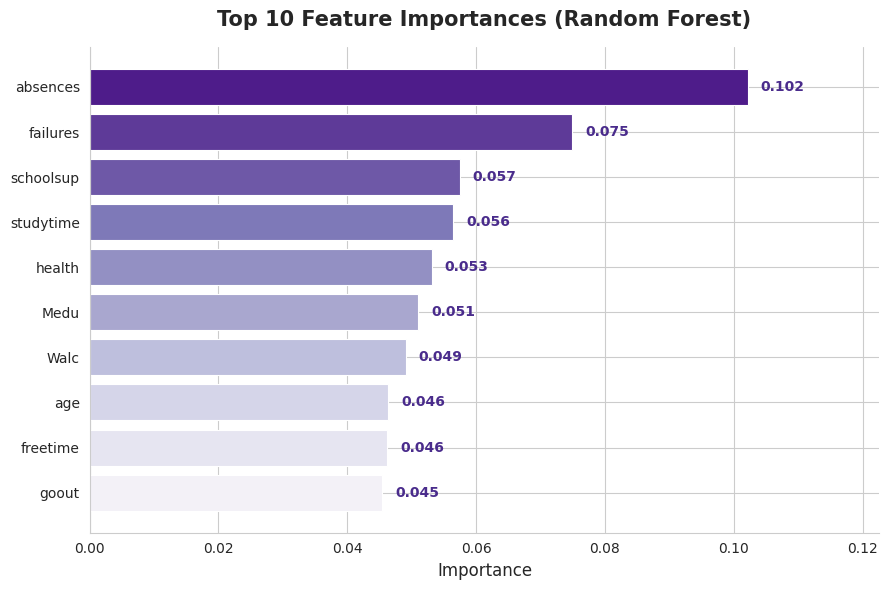

In [ ]:
#Visualization
sns.set_style("whitegrid")

top_n = 10
top_importances = importances.head(top_n).sort_values()

# Gradient color: darker purple = more important
colors = sns.color_palette("Purples", n_colors=top_n)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top_importances.index, top_importances.values, color=colors, edgecolor='white', linewidth=0.8)

# Add value labels at the end of each bar
for bar, val in zip(bars, top_importances.values):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2, f'{val:.3f}',
            va='center', fontsize=10, fontweight='bold', color="#4A2C8C")

ax.set_title("Top 10 Feature Importances (Random Forest)", fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel("Importance", fontsize=12)
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlim(0, top_importances.max() * 1.2)

plt.tight_layout()
plt.show()

In [ ]:
#Build regression models
#First: the train/test split
from sklearn.model_selection import train_test_split

X = df.drop(columns=['G3'])
if 'Student_ID' in X.columns:
    X = X.drop(columns=['Student_ID'])
y = df['G3']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(285, 39) (72, 39)


In [ ]:
#Model 1 — Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
pred_lr = lr.predict(X_test_scaled)

print("MAE:", mean_absolute_error(y_test, pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_lr)))
print("R²:", r2_score(y_test, pred_lr))

MAE: 2.323130801608228
RMSE: 2.773234162691913
R²: 0.20170492548917918


In [ ]:
#Model 2 — Decision Tree
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42, max_depth=5)
dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_dt)))
print("R²:", r2_score(y_test, pred_dt))

MAE: 2.513565263244339
RMSE: 3.2038981005739227
R²: -0.06548602193413289


In [ ]:
#Model 3 — the ensemble: Random Forest
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_rf)))
print("R²:", r2_score(y_test, pred_rf))

MAE: 2.22875
RMSE: 2.717367496514064
R²: 0.23354419237931257


In [ ]:
#hyperparameter tuning on the best model (Random Forest)
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print("Best CV R²:", grid_search.best_score_)

Best params: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 300}
Best CV R²: 0.13237603787074814


In [ ]:
best_rf = grid_search.best_estimator_
pred_best_rf = best_rf.predict(X_test)

print("Tuned RF — MAE:", mean_absolute_error(y_test, pred_best_rf))
print("Tuned RF — RMSE:", np.sqrt(mean_squared_error(y_test, pred_best_rf)))
print("Tuned RF — R²:", r2_score(y_test, pred_best_rf))

Tuned RF — MAE: 2.178410546793428
Tuned RF — RMSE: 2.7012694279469995
Tuned RF — R²: 0.24259847802655032


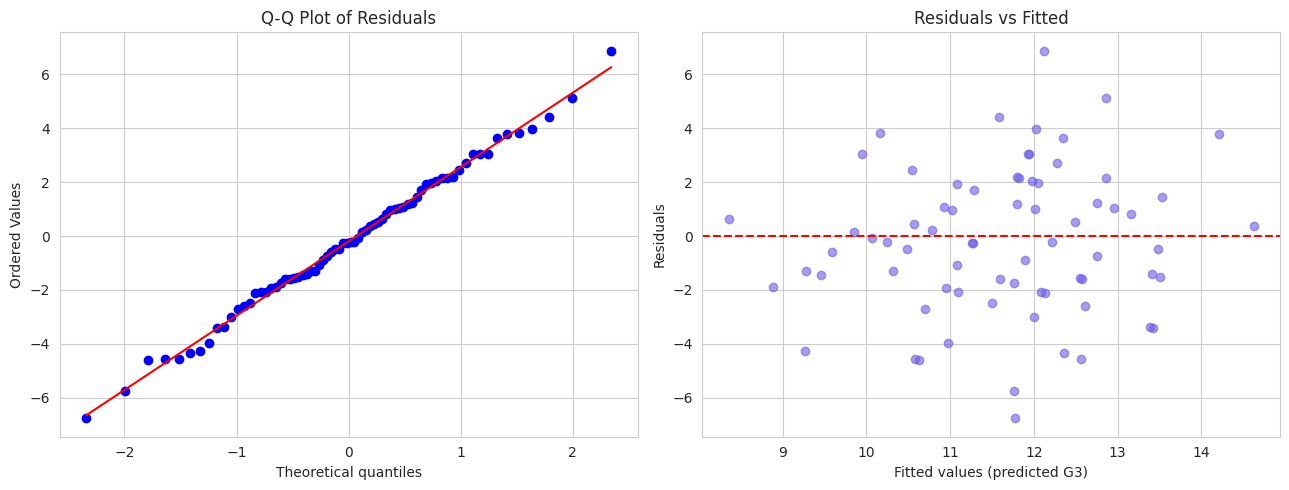

In [ ]:
#Residual Analysis
import scipy.stats as stats

residuals = y_test - pred_best_rf

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Q-Q plot for normality
stats.probplot(residuals, dist="norm", plot=axes[0])
axes[0].set_title("Q-Q Plot of Residuals")

# Residuals vs Fitted for homoscedasticity
axes[1].scatter(pred_best_rf, residuals, alpha=0.6, color="#6C5CE7")
axes[1].axhline(y=0, color='red', linestyle='--')
axes[1].set_xlabel("Fitted values (predicted G3)")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residuals vs Fitted")

plt.tight_layout()
plt.show()

In [ ]:
results_df = X_test.copy()
results_df['actual_G3'] = y_test.values
results_df['predicted_G3'] = pred_best_rf
results_df['abs_error'] = np.abs(results_df['actual_G3'] - results_df['predicted_G3'])

worst_predicted = results_df.sort_values('abs_error', ascending=False).head(15)
print(worst_predicted[['actual_G3', 'predicted_G3', 'abs_error', 'failures', 'absences', 'schoolsup']])

     actual_G3  predicted_G3  abs_error  failures  absences  schoolsup
113         19     12.116896   6.883104         0        10          0
338          5     11.772527   6.772527         0        14          0
82           6     11.763866   5.763866         0        10          0
277         18     12.861074   5.138926         0         0          0
185          6     10.623058   4.623058         0        18          0
45           6     10.583552   4.583552         0         8          1
90           8     12.558464   4.558464         0         0          0
353         16     11.580390   4.419610         0         3          0
124          8     12.359400   4.359400         0         0          0
72           5      9.271027   4.271027         2         2          1
182         16     12.026804   3.973196         0         2          0
346          7     10.969416   3.969416         0         5          0
139         14     10.157326   3.842674         1         6          0
42    

In [ ]:
#Classification (predicting timely graduation)
df['graduation_status'] = np.where(df['G3'] >= 10, 'Graduate on Time', 'At Risk')

print(df['graduation_status'].value_counts())
print(df['graduation_status'].value_counts(normalize=True))

graduation_status
Graduate on Time    265
At Risk              92
Name: count, dtype: int64
graduation_status
Graduate on Time    0.742297
At Risk             0.257703
Name: proportion, dtype: float64


/tmp/ipykernel_2131/796610762.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='graduation_status', y='failures', data=df, ax=axes[1], palette="pastel")
/tmp/ipykernel_2131/796610762.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='graduation_status', y='absences', data=df, ax=axes[2], palette="pastel")


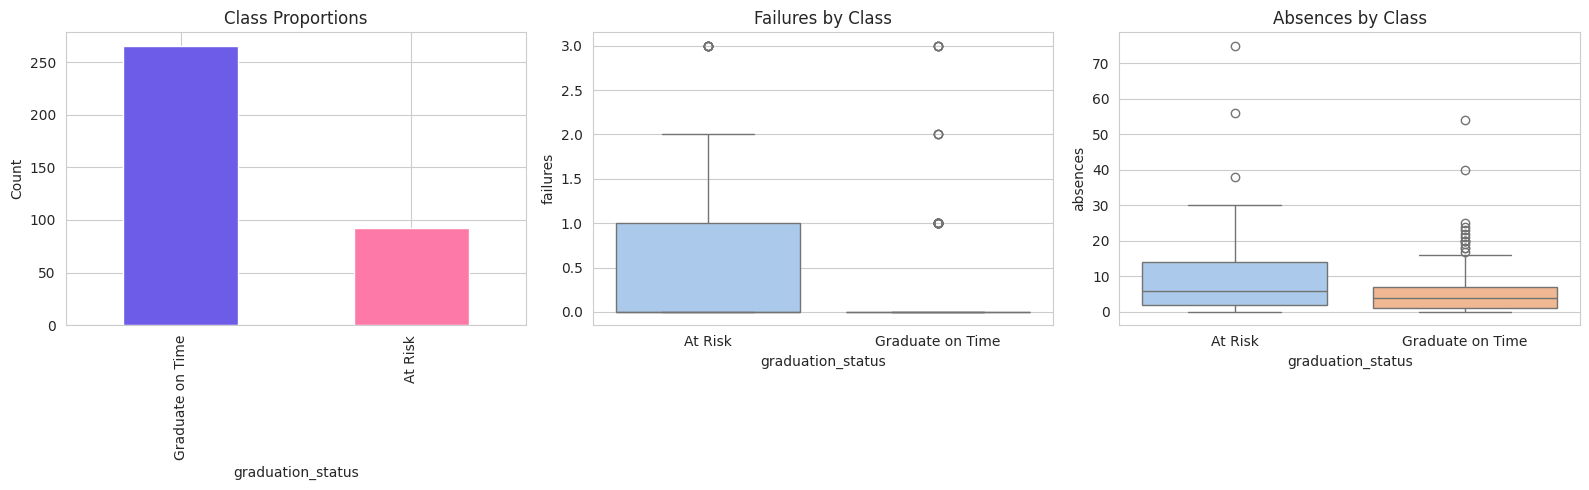

In [ ]:
sns.set_style("whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Class proportions
df['graduation_status'].value_counts().plot(kind='bar', ax=axes[0], color=["#6C5CE7", "#FD79A8"])
axes[0].set_title("Class Proportions")
axes[0].set_ylabel("Count")

# Feature distribution by class — pick 2 features we know matter from D1
sns.boxplot(x='graduation_status', y='failures', data=df, ax=axes[1], palette="pastel")
axes[1].set_title("Failures by Class")

sns.boxplot(x='graduation_status', y='absences', data=df, ax=axes[2], palette="pastel")
axes[2].set_title("Absences by Class")

plt.tight_layout()
plt.show()

In [ ]:
#Statistical tests (Mann-Whitney U test)
from scipy.stats import mannwhitneyu, chi2_contingency

# --- Mann-Whitney U tests (numerical features) ---
numeric_test_cols = ['failures', 'absences', 'studytime']

for col in numeric_test_cols:
    group_risk = df[df['graduation_status'] == 'At Risk'][col]
    group_ontime = df[df['graduation_status'] == 'Graduate on Time'][col]
    stat, p = mannwhitneyu(group_risk, group_ontime, alternative='two-sided')
    print(f"{col}: U-statistic={stat:.2f}, p-value={p:.5f}")

print()

# --- Chi-square tests (categorical features) ---
cat_test_cols = ['schoolsup', 'higher']

for col in cat_test_cols:
    contingency = pd.crosstab(df[col], df['graduation_status'])
    chi2, p, dof, expected = chi2_contingency(contingency)
    print(f"{col}: chi2={chi2:.2f}, p-value={p:.5f}")

failures: U-statistic=15132.50, p-value=0.00000
absences: U-statistic=15801.50, p-value=0.00002
studytime: U-statistic=11169.00, p-value=0.19316

schoolsup: chi2=9.02, p-value=0.00267
higher: chi2=3.25, p-value=0.07139


In [ ]:
#Preprocessing pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Target: use the raw (unencoded) graduation_status, binary-encode it
y_clf = (df['graduation_status'] == 'At Risk').astype(int)  # 1 = At Risk, 0 = Graduate on Time

# Use the same feature set as D1 (already encoded), but drop G3/graduation_status/G1/G2 if present
drop_cols = ['G3', 'graduation_status']
X_clf = df.drop(columns=[c for c in drop_cols if c in df.columns])

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)
print(X_train_c.shape, X_test_c.shape)
print(y_train_c.value_counts())

(285, 39) (72, 39)
graduation_status
0    212
1     73
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LogisticRegression
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),   # no-op here since no missing values, but satisfies the requirement
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

pipeline.fit(X_train_c, y_train_c)
pred_c = pipeline.predict(X_test_c)

from sklearn.metrics import classification_report
print(classification_report(y_test_c, pred_c))

              precision    recall  f1-score   support

           0       0.82      0.85      0.83        53
           1       0.53      0.47      0.50        19

    accuracy                           0.75        72
   macro avg       0.67      0.66      0.67        72
weighted avg       0.74      0.75      0.75        72



In [ ]:
#Decision Tree Model
from sklearn.tree import DecisionTreeClassifier

pipeline_dt = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42))
])

pipeline_dt.fit(X_train_c, y_train_c)
pred_dt_c = pipeline_dt.predict(X_test_c)
print(classification_report(y_test_c, pred_dt_c))

              precision    recall  f1-score   support

           0       0.75      0.77      0.76        53
           1       0.29      0.26      0.28        19

    accuracy                           0.64        72
   macro avg       0.52      0.52      0.52        72
weighted avg       0.63      0.64      0.63        72



In [ ]:
#Random Forest Model
from sklearn.ensemble import RandomForestClassifier

pipeline_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(class_weight='balanced', n_estimators=200, random_state=42))
])

pipeline_rf.fit(X_train_c, y_train_c)
pred_rf_c = pipeline_rf.predict(X_test_c)
print(classification_report(y_test_c, pred_rf_c))

              precision    recall  f1-score   support

           0       0.74      0.98      0.85        53
           1       0.50      0.05      0.10        19

    accuracy                           0.74        72
   macro avg       0.62      0.52      0.47        72
weighted avg       0.68      0.74      0.65        72



In [ ]:
#Hyperparameter tuning with RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

param_dist = {
    'classifier__C': np.logspace(-3, 2, 50),          # regularization strength
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear']                 # liblinear supports both l1 and l2
}

random_search = RandomizedSearchCV(
    pipeline,                     # your original Logistic Regression pipeline
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='f1',                 # optimize for F1 on class 1 (the positive/minority class by default... see note below)
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_c, y_train_c)

print("Best params:", random_search.best_params_)
print("Best CV F1:", random_search.best_score_)

Best params: {'classifier__solver': 'liblinear', 'classifier__penalty': 'l2', 'classifier__C': np.float64(0.016768329368110083)}
Best CV F1: 0.4682435211846977


In [ ]:
best_lr = random_search.best_estimator_
pred_best_lr = best_lr.predict(X_test_c)
print(classification_report(y_test_c, pred_best_lr))

              precision    recall  f1-score   support

           0       0.82      0.79      0.81        53
           1       0.48      0.53      0.50        19

    accuracy                           0.72        72
   macro avg       0.65      0.66      0.65        72
weighted avg       0.73      0.72      0.73        72



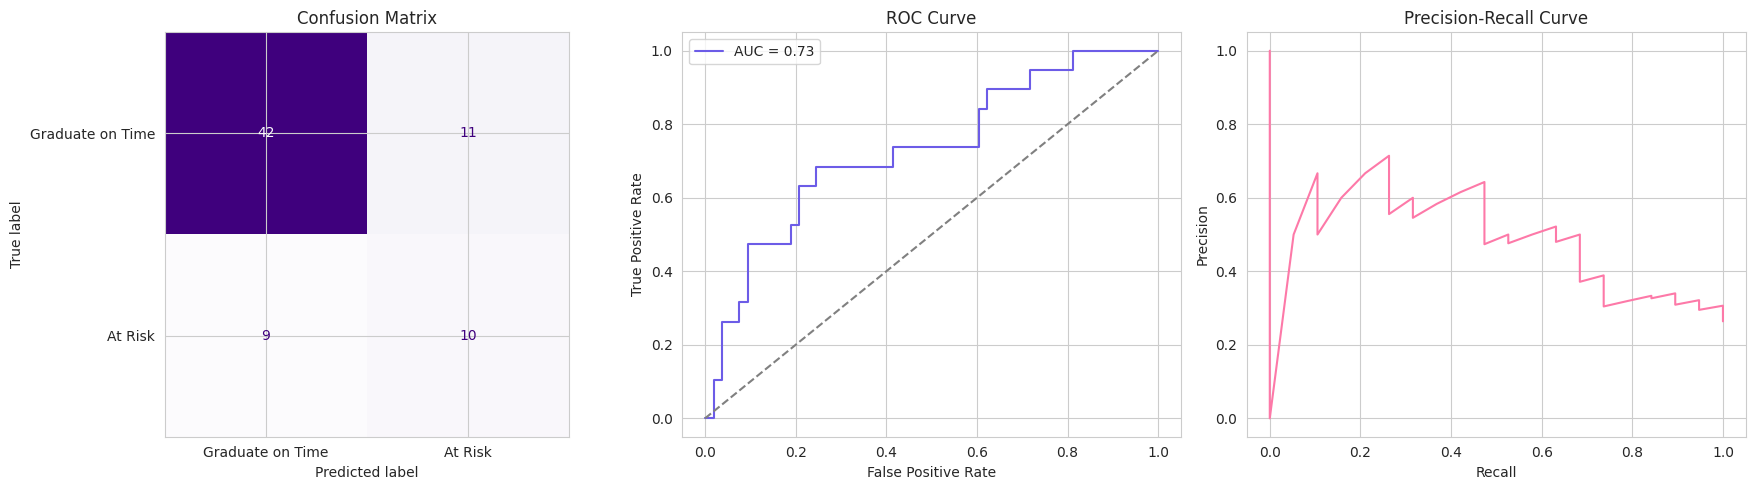

In [ ]:
#Full evaluation suite
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, precision_recall_curve

# Need predicted probabilities for ROC/PR curves
y_proba = best_lr.predict_proba(X_test_c)[:, 1]  # probability of class 1 (At Risk)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test_c, pred_best_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Graduate on Time', 'At Risk'])
disp.plot(ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title("Confusion Matrix")

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test_c, y_proba)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color="#6C5CE7", label=f'AUC = {roc_auc:.2f}')
axes[1].plot([0,1], [0,1], linestyle='--', color='gray')
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve")
axes[1].legend()

# 3. Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test_c, y_proba)
axes[2].plot(recall, precision, color="#FD79A8")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

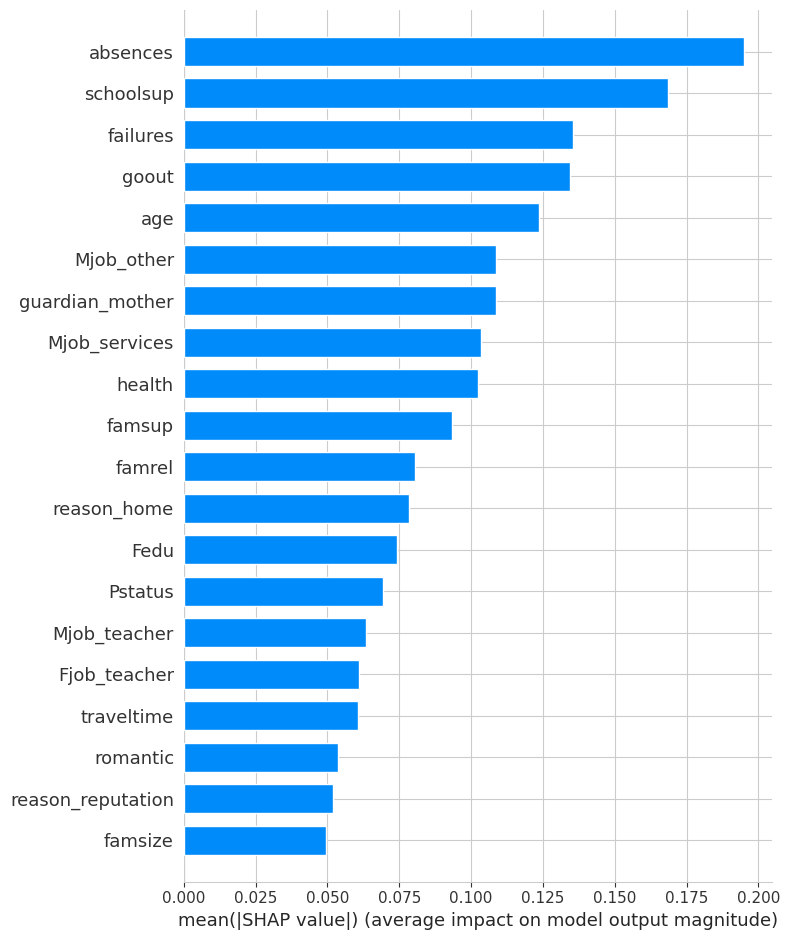

In [ ]:
#Model interpretation — SHAP or feature importance
import shap

explainer = shap.LinearExplainer(best_lr.named_steps['classifier'],
                                   best_lr.named_steps['scaler'].transform(
                                       best_lr.named_steps['imputer'].transform(X_train_c)))
X_test_transformed = best_lr.named_steps['scaler'].transform(
    best_lr.named_steps['imputer'].transform(X_test_c))

shap_values = explainer.shap_values(X_test_transformed)

shap.summary_plot(shap_values, X_test_c, plot_type="bar", show=False)
import matplotlib.pyplot as plt
plt.tight_layout()
plt.show()

In [ ]:
#Clustering assignment (Student Learning Pattern Segmentation)
#select and standardize:

cluster_features = ['studytime', 'absences', 'goout', 'freetime', 'traveltime', 'G3']
X_cluster = df[cluster_features].copy()

scaler_c = StandardScaler()
X_cluster_scaled = scaler_c.fit_transform(X_cluster)

print(X_cluster.describe())

        studytime    absences       goout    freetime  traveltime          G3
count  357.000000  357.000000  357.000000  357.000000  357.000000  357.000000
mean     2.042017    6.316527    3.098039    3.246499    1.431373   11.523810
std      0.831895    8.187623    1.090779    1.011601    0.686075    3.227797
min      1.000000    0.000000    1.000000    1.000000    1.000000    4.000000
25%      1.000000    2.000000    2.000000    3.000000    1.000000    9.000000
50%      2.000000    4.000000    3.000000    3.000000    1.000000   11.000000
75%      2.000000    8.000000    4.000000    4.000000    2.000000   14.000000
max      4.000000   75.000000    5.000000    5.000000    4.000000   20.000000


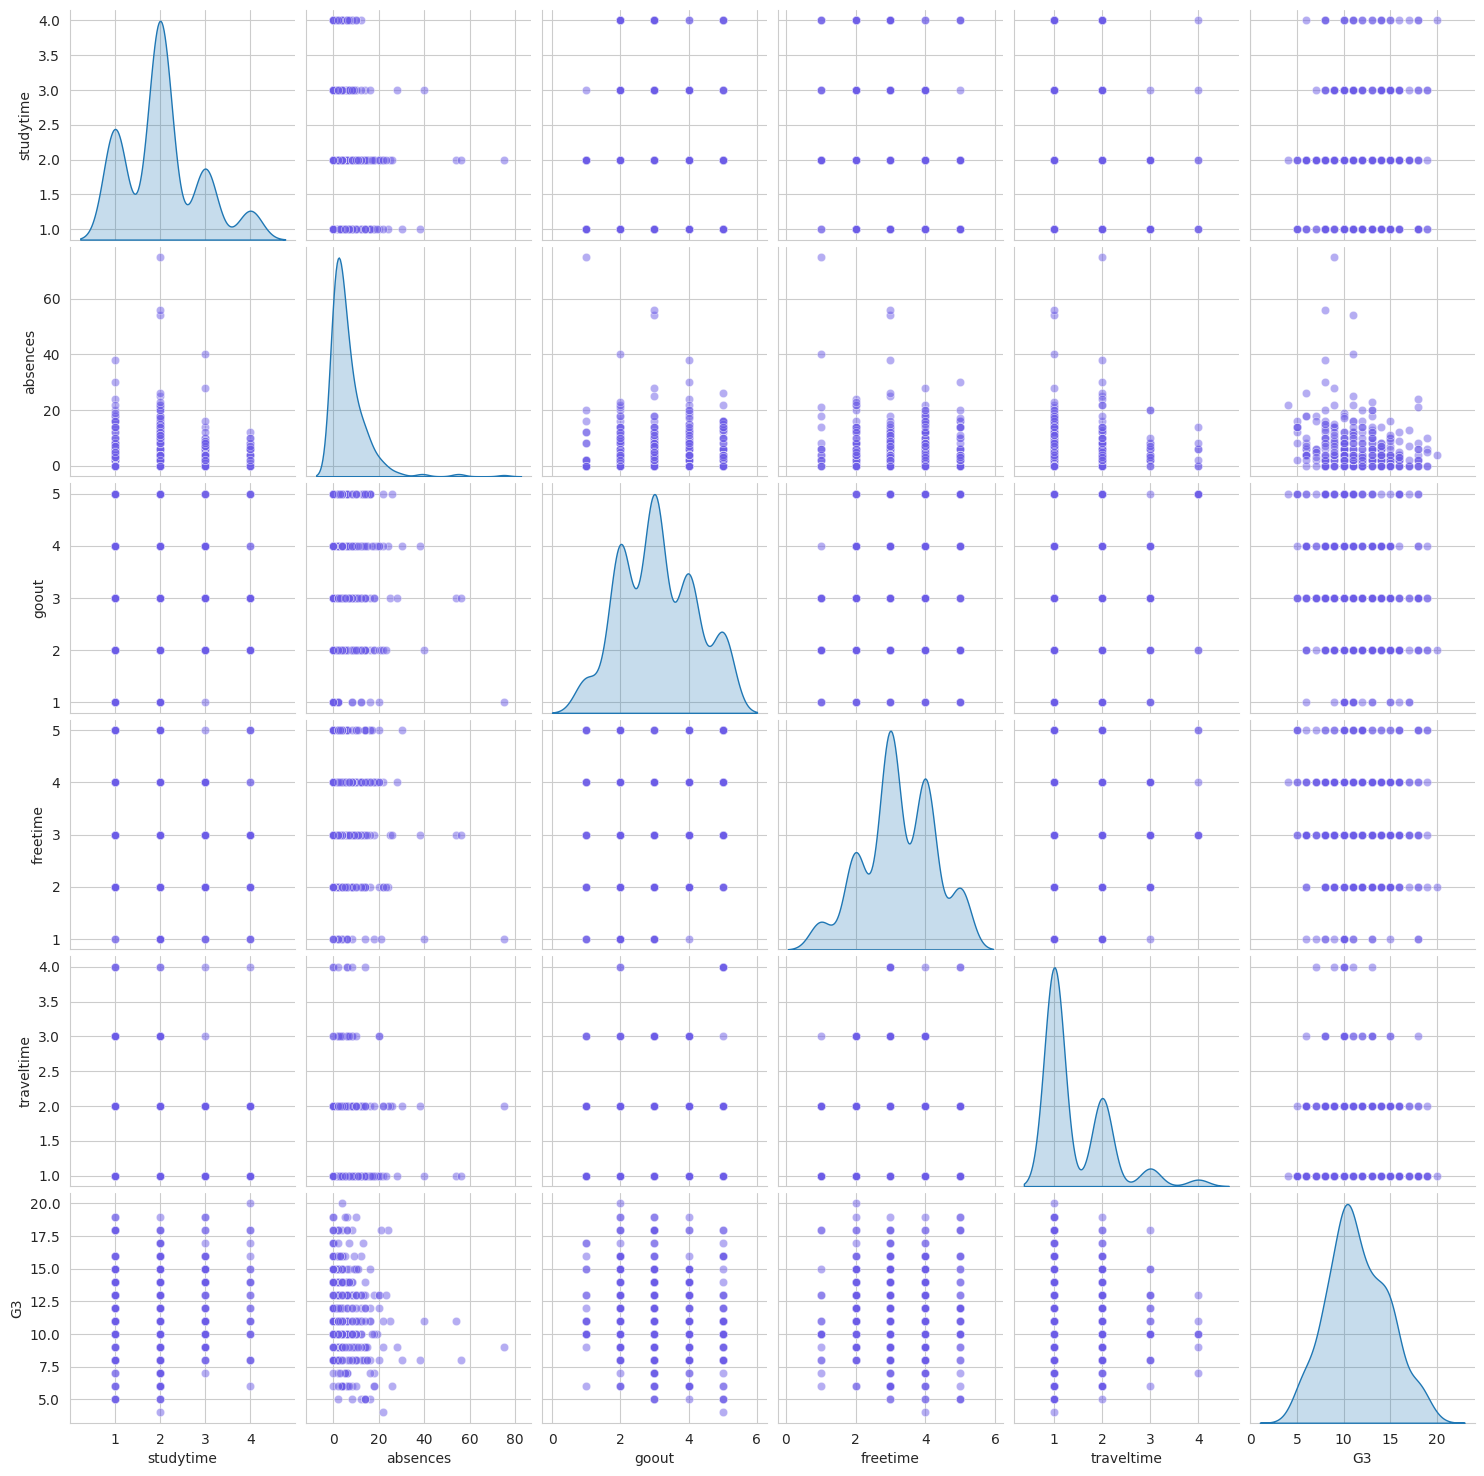

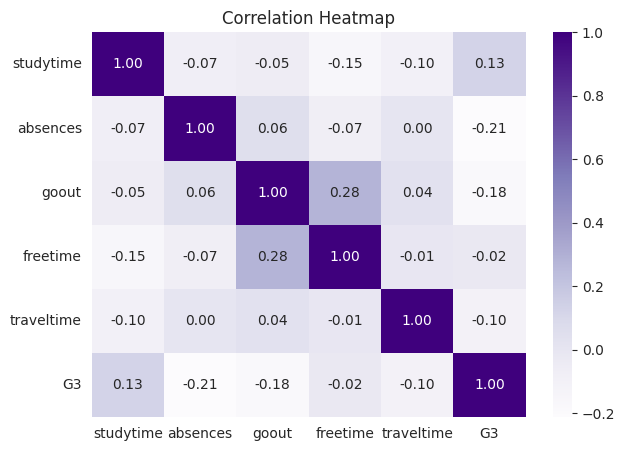

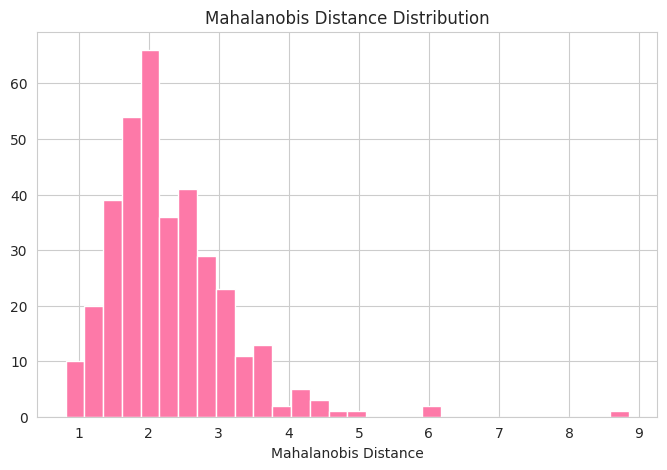

Number of multivariate outliers: 15


In [ ]:
#Initial exploration
# Pair plot
sns.pairplot(X_cluster, diag_kind='kde', plot_kws={'alpha':0.5, 'color':'#6C5CE7'})
plt.show()

# Correlation heatmap
plt.figure(figsize=(7,5))
sns.heatmap(X_cluster.corr(), annot=True, cmap='Purples', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

# Mahalanobis distance for multivariate outliers
from scipy.spatial.distance import mahalanobis
import numpy as np

cov_matrix = np.cov(X_cluster_scaled, rowvar=False)
inv_cov_matrix = np.linalg.inv(cov_matrix)
mean_vec = X_cluster_scaled.mean(axis=0)

mahal_dist = np.array([mahalanobis(row, mean_vec, inv_cov_matrix) for row in X_cluster_scaled])

plt.figure(figsize=(8,5))
plt.hist(mahal_dist, bins=30, color='#FD79A8', edgecolor='white')
plt.title("Mahalanobis Distance Distribution")
plt.xlabel("Mahalanobis Distance")
plt.show()

# Flag outliers using chi-square threshold (common convention: 97.5th percentile)
from scipy.stats import chi2
threshold = chi2.ppf(0.975, df=len(cluster_features))
outliers = mahal_dist > np.sqrt(threshold)
print(f"Number of multivariate outliers: {outliers.sum()}")

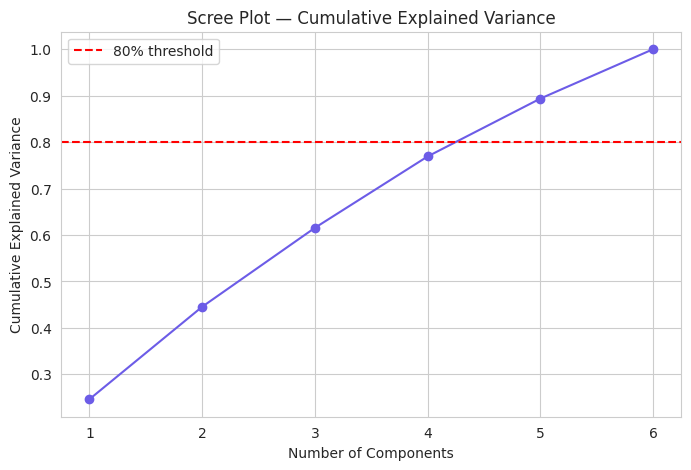

[0.24627183 0.19912254 0.17000438 0.15368925 0.12461689 0.10629511]
[0.24627183 0.44539437 0.61539874 0.76908799 0.89370489 1.        ]


In [ ]:
#PCA
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(X_cluster_scaled)

explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

plt.figure(figsize=(8,5))
plt.plot(range(1, len(explained_var)+1), cumulative_var, marker='o', color="#6C5CE7")
plt.axhline(y=0.8, color='red', linestyle='--', label='80% threshold')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Scree Plot — Cumulative Explained Variance")
plt.legend()
plt.show()

print(explained_var)
print(cumulative_var)

In [ ]:
pca_2 = PCA(n_components=2)
X_pca = pca_2.fit_transform(X_cluster_scaled)

print("Explained variance by PC1, PC2:", pca_2.explained_variance_ratio_)
print("Total captured:", pca_2.explained_variance_ratio_.sum())

# Loadings — which original features dominate each component
loadings = pd.DataFrame(
    pca_2.components_.T,
    columns=['PC1', 'PC2'],
    index=cluster_features
)
print(loadings)

Explained variance by PC1, PC2: [0.24627183 0.19912254]
Total captured: 0.4453943664175678
                 PC1       PC2
studytime  -0.408404  0.023795
absences    0.288619 -0.579380
goout       0.526099  0.311469
freetime    0.418926  0.608352
traveltime  0.222754 -0.194923
G3         -0.498003  0.398312


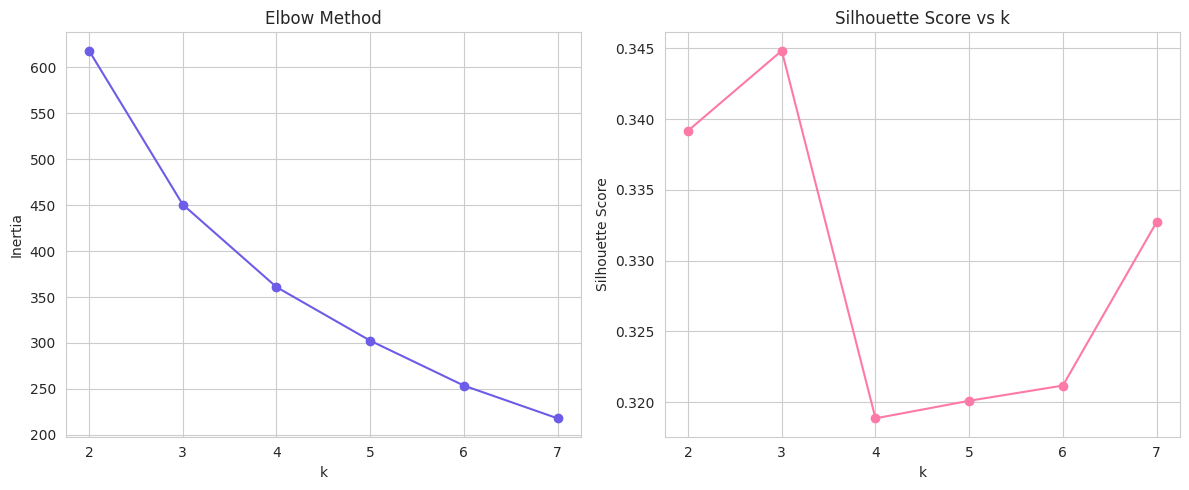

[(2, np.float64(0.33918834668114456)), (3, np.float64(0.3448433124617256)), (4, np.float64(0.3188491668328748)), (5, np.float64(0.32009149392087377)), (6, np.float64(0.32116649868346336)), (7, np.float64(0.3327213250892387))]


In [ ]:
#Run K-Means and GMM on the PCA-transformed data, compare 3 validity metrics
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_range = range(2, 8)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_pca, labels))

fig, axes = plt.subplots(1, 2, figsize=(12,5))
axes[0].plot(k_range, inertias, marker='o', color="#6C5CE7")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_range, silhouette_scores, marker='o', color="#FD79A8")
axes[1].set_title("Silhouette Score vs k")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print(list(zip(k_range, silhouette_scores)))

In [ ]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

k_final = 3

# K-Means
km_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
km_labels = km_final.fit_predict(X_pca)

# GMM
gmm_final = GaussianMixture(n_components=k_final, random_state=42)
gmm_labels = gmm_final.fit_predict(X_pca)

# Metrics for both
for name, labels in [('K-Means', km_labels), ('GMM', gmm_labels)]:
    sil = silhouette_score(X_pca, labels)
    ch = calinski_harabasz_score(X_pca, labels)
    db = davies_bouldin_score(X_pca, labels)
    print(f"{name}: Silhouette={sil:.4f}, Calinski-Harabasz={ch:.2f}, Davies-Bouldin={db:.4f}")

K-Means: Silhouette=0.3448, Calinski-Harabasz=197.76, Davies-Bouldin=0.9723
GMM: Silhouette=0.2927, Calinski-Harabasz=132.03, Davies-Bouldin=1.3253


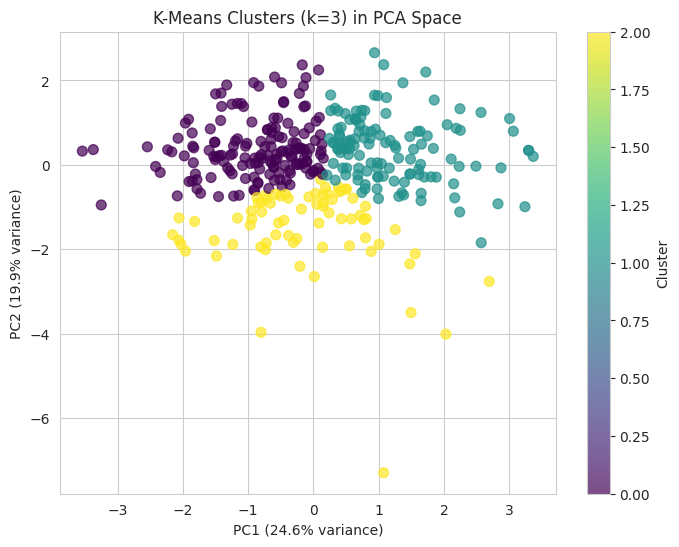

         studytime   absences     goout  freetime  traveltime         G3
cluster                                                                 
0         2.352201   3.031447  2.691824  3.176101    1.245283  13.559748
1         1.696000   6.744000  4.008000  3.904000    1.544000   9.888000
2         1.958904  12.739726  2.424658  2.273973    1.643836   9.890411


In [ ]:
#Visualize K-Means clusters in 2D (PCA space) + radar chart of cluster profiles
plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=km_labels, cmap='viridis', alpha=0.7, s=50)
plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("K-Means Clusters (k=3) in PCA Space")
plt.colorbar(scatter, label='Cluster')
plt.show()

# Attach cluster labels back to original data for profiling
df_clustered = df.copy()
df_clustered = df_clustered.loc[X_cluster.index]  # align indices just in case
df_clustered['cluster'] = km_labels

cluster_profile = df_clustered.groupby('cluster')[cluster_features].mean()
print(cluster_profile)

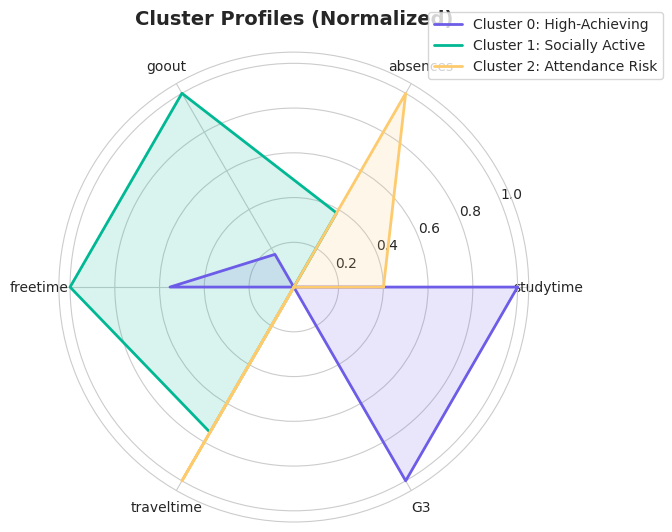

In [ ]:
#he radar chart
categories = cluster_features
n_vars = len(categories)

# Normalize each feature 0-1 for fair radar comparison (different scales otherwise)
profile_norm = (cluster_profile - cluster_profile.min()) / (cluster_profile.max() - cluster_profile.min())

angles = np.linspace(0, 2*np.pi, n_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7,7), subplot_kw=dict(polar=True))

colors = ['#6C5CE7', '#00B894', '#FDCB6E']
labels = ['Cluster 0: High-Achieving', 'Cluster 1: Socially Active', 'Cluster 2: Attendance Risk']

for i in range(3):
    values = profile_norm.iloc[i].tolist()
    values += values[:1]
    ax.plot(angles, values, color=colors[i], linewidth=2, label=labels[i])
    ax.fill(angles, values, color=colors[i], alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)
ax.set_title("Cluster Profiles (Normalized)", size=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

plt.tight_layout()
plt.show()